<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/classification1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Data

The dataset is at `solutions/galaxyquasar.csv`.

(If you've never used [SQL](https://en.wikipedia.org/wiki/SQL) and want to learn something new in computing, it's very powerful)

#### Tasks

- Create arrays for the $(u-g)$, $(g-r)$, $(r-i)$, and $(i-z)$ colors. Also create an array with the class labels where galaxy=$0$ and quasar=$1$.
- Classify the dataset against the target label.
- Try some of the classification methods we've seen so far and evaluate the performance using the ROC curve.
- Remember to split the dataset into training and validation...

#### Ideas
- Try using different colors (a subset of them first, than all together). Which is the most important feature?
- What are the colors that better satisfy or invalidate the "Naive" assumption of independence between the attributes?


In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from matplotlib import pyplot as plt


df = pd.read_csv('galaxyquasar.csv')

u_g = (df['u'].values - df['g'].values)
g_r = (df['g'].values - df['r'].values)
r_i = (df['r'].values - df['i'].values)
i_z = (df['i'].values - df['z'].values)

X_colors = np.column_stack((u_g, g_r, r_i, i_z)).T

le= LabelEncoder()
labels = le.fit_transform(df['class']) # galaxy = 0 and quasar = 1


plotting the arrays

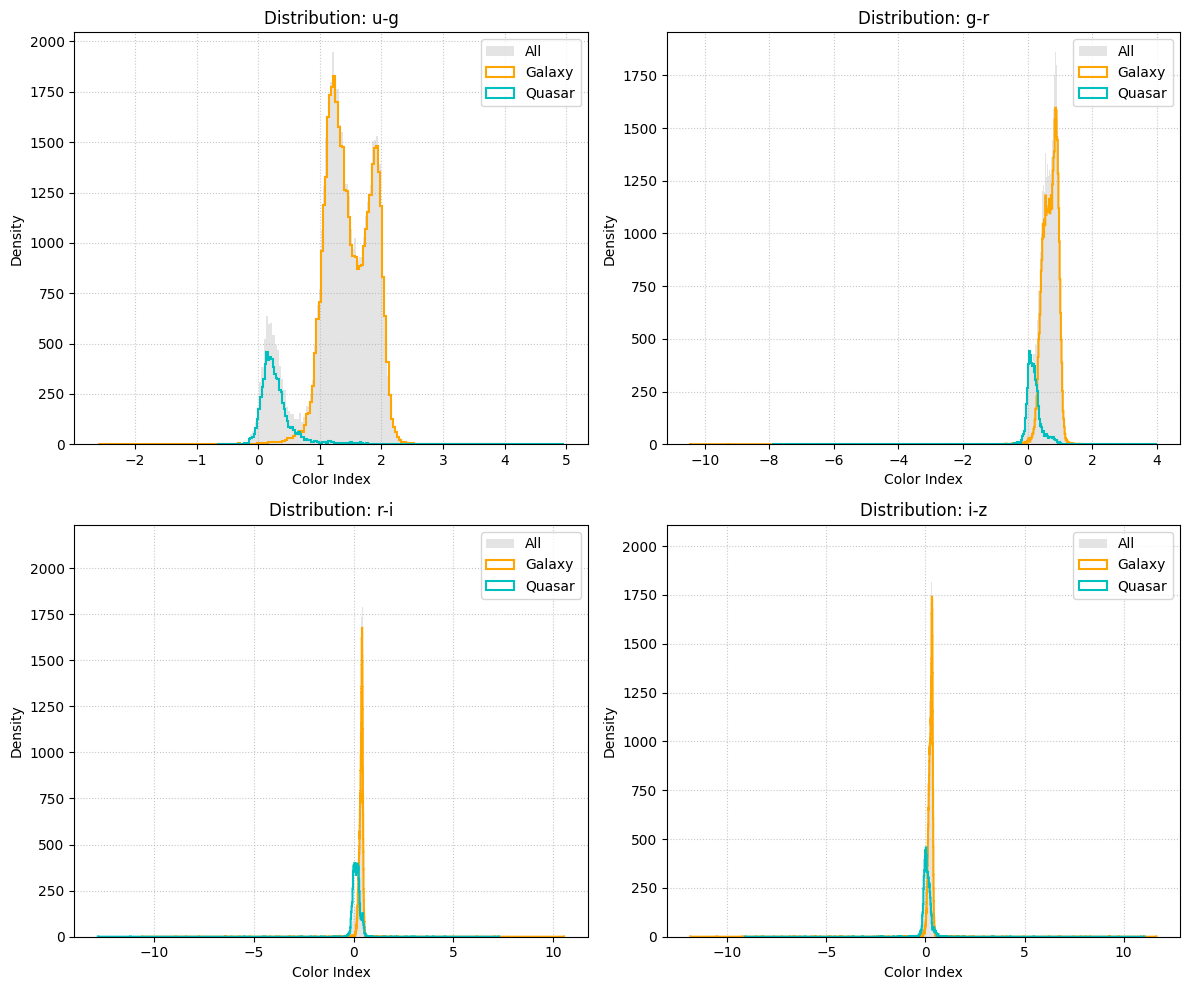

In [2]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
ax = ax.ravel()
color_names = ['u-g', 'g-r', 'r-i', 'i-z']



for i, (a, color_name) in enumerate(zip(ax, color_names)):
    galaxy_mask = (labels == 0)
    quasar_mask = (labels == 1)
    data = X_colors[i,:]
    a.hist(data, bins='fd', color='lightgray', label='All', alpha=0.6)

    a.hist(data[galaxy_mask], bins='fd', color='orange', histtype='step', label='Galaxy', linewidth=1.5)
    a.hist(data[quasar_mask], bins='fd', color='c', histtype='step', label='Quasar', linewidth=1.5)

    a.set_title(f'Distribution: {color_name}')
    a.set_xlabel('Color Index')
    a.set_ylabel('Density')
    a.grid(True, linestyle=':', alpha=0.7)
    a.legend()

plt.tight_layout()
plt.show()

GAUSSIAN NAIVE BAYESIAN

SINGLE ARRAY

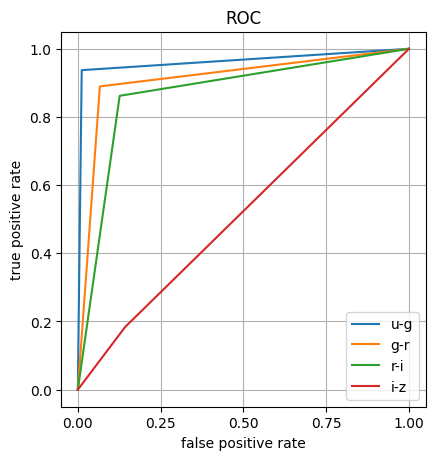

In [3]:
from sklearn.naive_bayes import GaussianNB
from astroML.utils import split_samples
from sklearn.metrics import roc_curve,precision_recall_curve

def GNB(data,labels):
  (X_train, X_test), (y_train, y_test) = split_samples(data, labels, [0.75, 0.35], #1/4 test 3/4 train
                                                     random_state=0)
  gnb = GaussianNB()
  gnb.fit(X_train, y_train)
  y_pred = gnb.predict(X_test)
  return y_pred, y_test


def param(data,labels):
  y_pred,y_test=GNB(data,labels)
  fpr, tpr, thresh = roc_curve(y_pred,y_test)
  # add (0, 0) as first point
  fpr = np.concatenate([[0], fpr])
  tpr = np.concatenate([[0], tpr])
  return fpr,tpr
#plotting
fig = plt.figure(figsize=(15, 5))
fig.subplots_adjust(left=0.1, right=0.95, bottom=0.15, top=0.9, wspace=0.25)


# ax1 will show roc curves
ax1 = plt.subplot(131)

for data,color in zip( X_colors,color_names):
  fpr,tpr=param(data.reshape(-1,1),labels)
  ax1.plot(fpr, tpr,label=color)

ax1.xaxis.set_major_locator(plt.MaxNLocator(5))
ax1.set_xlabel('false positive rate')
ax1.set_ylabel('true positive rate')
ax1.legend(loc=4)
plt.title('ROC')
plt.grid()




**COMPLETE DATASET**

/tmp/ipykernel_2418/1013639410.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend(loc=4)


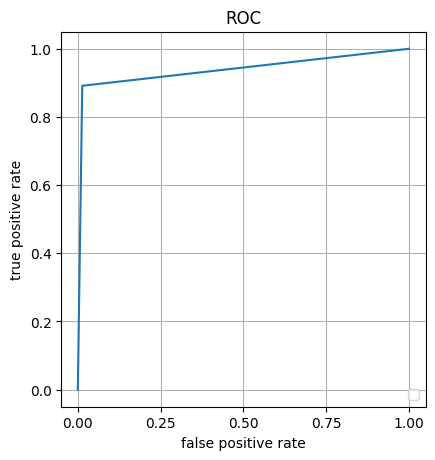

In [4]:
#plotting
fig = plt.figure(figsize=(15, 5))
fig.subplots_adjust(left=0.1, right=0.95, bottom=0.15, top=0.9, wspace=0.25)


# ax1 will show roc curves
ax1 = plt.subplot(131)
fpr,tpr=param(X_colors.T,labels)
ax1.plot(fpr, tpr)

ax1.xaxis.set_major_locator(plt.MaxNLocator(5))
ax1.set_xlabel('false positive rate')
ax1.set_ylabel('true positive rate')
ax1.legend(loc=4)
plt.title('ROC')
plt.grid()


comparing methods

GaussianNB
LinearDiscriminantAnalysis
QuadraticDiscriminantAnalysis
LogisticRegression
KNeighborsClassifier
GMMBayes


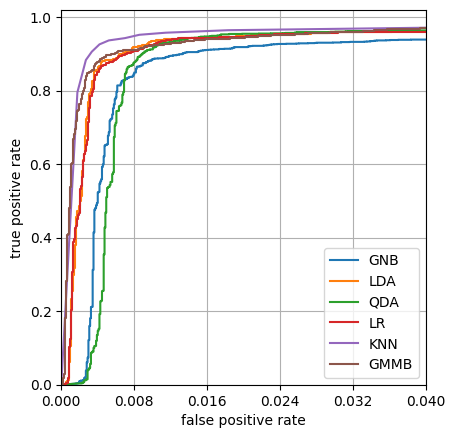

In [5]:
from sklearn.discriminant_analysis import (LinearDiscriminantAnalysis,
                                           QuadraticDiscriminantAnalysis)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from astroML.classification import GMMBayes
from astroML.utils import split_samples, completeness_contamination



def compute_models(*args):
    names = []
    probs = []
    for classifier, kwargs in args:
        print(classifier.__name__)
        clf = classifier(**kwargs)
        clf.fit(X_train, y_train)

        #Note that we are outputing the probabilities [of class 1], not the classes
        y_probs = clf.predict_proba(X_test)[:, 1]

        names.append(classifier.__name__)
        probs.append(y_probs)

    return names, probs

(X_train, X_test), (y_train, y_test) = split_samples(X_colors.T, labels, [0.75, 0.25],
                                                     random_state=0)


names, probs = compute_models((GaussianNB, {}),
                              (LinearDiscriminantAnalysis, {}),
                              (QuadraticDiscriminantAnalysis, {}),
                              (LogisticRegression,
                               dict(class_weight='balanced')),
                              (KNeighborsClassifier,
                               dict(n_neighbors=10)),
                              (GMMBayes, dict(n_components=3, tol=1E-5,
                                              covariance_type='full')))
#------------------------------------------------------------
# Plot ROC curves and completeness/efficiency
fig = plt.figure(figsize=(15, 5))
fig.subplots_adjust(left=0.1, right=0.95, bottom=0.15, top=0.9, wspace=0.25)

# ax1 will show roc curves
ax1 = plt.subplot(131)

# ax2 will show completeness/efficiency
#ax2 = plt.subplot(132)

# ax3 will show precision/recall
# ax3 = plt.subplot(133)

labelss = dict(GaussianNB='GNB',
              LinearDiscriminantAnalysis='LDA',
              QuadraticDiscriminantAnalysis='QDA',
              KNeighborsClassifier='KNN',
              DecisionTreeClassifier='DT',
              GMMBayes='GMMB',
              LogisticRegression='LR')

thresholds = np.linspace(0, 1, 1001)[:-1]

# iterate through and show results
for name, y_prob in zip(names, probs):
    fpr, tpr, thresh = roc_curve(y_test, y_prob)
    precision, recall, thresh2 = precision_recall_curve(y_test, y_prob)

    # add (0, 0) as first point
    fpr = np.concatenate([[0], fpr])
    tpr = np.concatenate([[0], tpr])
    # Here we add (1,0)
    precision = np.concatenate([[0], precision])
    recall = np.concatenate([[1], recall])
    thresh2 = np.concatenate([[0], thresh2])

    ax1.plot(fpr, tpr,label=labelss[name])
'''
    #See note above about astroML vs. sklearn
    #Note that the range of threshhold values here is 0% to 100% (0.0 to 1.0)
    comp = np.zeros_like(thresholds)
    cont = np.zeros_like(thresholds)
    for i, t in enumerate(thresholds):
        y_pred = (y_prob >= t)
        comp[i], cont[i] = completeness_contamination(y_pred, y_test)
    ax2.plot(1 - cont, comp,label=labelss[name])

    #ax3.plot(precision, recall, label=labels[name])
'''
ax1.set_xlim(0, 0.04)
ax1.set_ylim(0, 1.02)
ax1.xaxis.set_major_locator(plt.MaxNLocator(5))
ax1.set_xlabel('false positive rate')
ax1.set_ylabel('true positive rate')
ax1.legend(loc=4)
'''
ax2.set_xlabel('efficiency')
ax2.set_ylabel('completeness')
ax2.set_xlim(0, 1.0)
ax2.set_ylim(0.2, 1.02)

#ax3.set_xlabel('precision')
#ax3.set_ylabel('recall')
#ax3.set_xlim(0, 1.0)
#ax3.set_ylim(0.2, 1.02)
'''
plt.grid()
plt.show()

IMPLEMENTING KNN

In [6]:
KN =  KNeighborsClassifier()
KN.fit(X_train, y_train)
y_pred_KN = KN.predict(X_test)

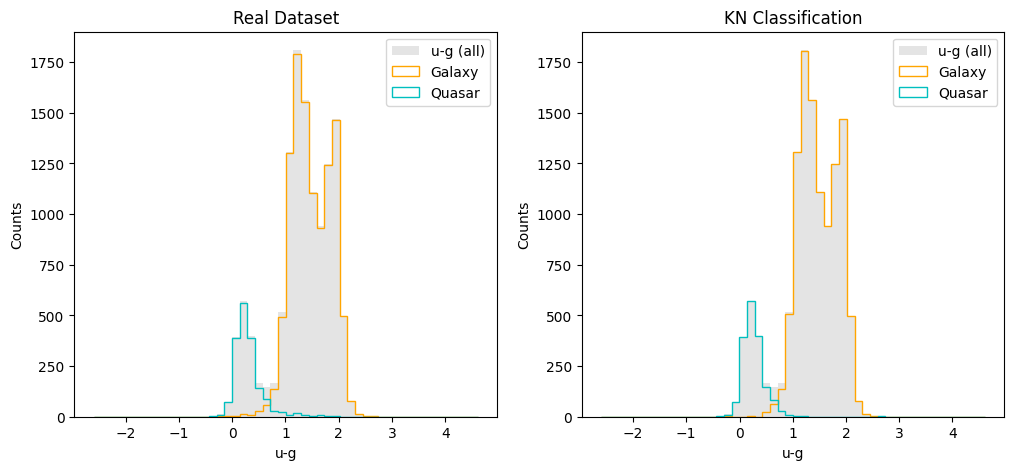

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes = axes.ravel()

# Shared bin edges for all three histograms

bins = np.linspace(X_test[:, 0].min(), X_test[:, 0].max(), 51)

axes[0].hist(X_test[:, 0], bins=bins, color='lightgray', label='u-g (all)', alpha=0.6, density=False)
axes[0].hist(X_test[:, 0][y_test == 0], bins=bins, color='orange', histtype='step', label='Galaxy', density=False)
axes[0].hist(X_test[:, 0][y_test == 1], bins=bins, color='c', histtype='step', label='Quasar', density=False)

axes[0].set_title('Real Dataset')
axes[0].set_xlabel('u-g')
axes[0].set_ylabel('Counts')
axes[0].legend()

axes[1].hist(X_test[:, 0], bins=bins, color='lightgray', label='u-g (all)', alpha=0.6, density=False)
axes[1].hist(X_test[:, 0][y_pred_KN == 0], bins=bins, color='orange', histtype='step', label='Galaxy', density=False)
axes[1].hist(X_test[:, 0][y_pred_KN == 1], bins=bins, color='c', histtype='step', label='Quasar', density=False)

axes[1].set_title('KN Classification')
axes[1].set_xlabel('u-g')
axes[1].set_ylabel('Counts')
axes[1].legend()

plt.show()

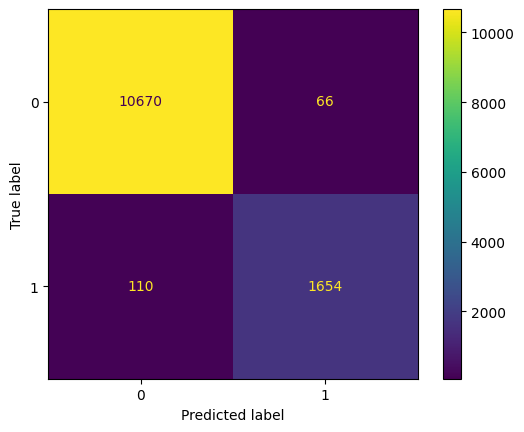

Decision Tree accuracy: 0.98592
Completeness: 0.9376
Contamination: 0.0384


In [8]:
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, y_pred_KN)
disp_KN = ConfusionMatrixDisplay(confusion_matrix=cm)
disp_KN.plot()
plt.show()

tn_KN, fp_KN, fn_KN, tp_KN = confusion_matrix(y_test, y_pred_KN).ravel()
completeness_KN = tp_KN / (tp_KN + fn_KN)
contamination_KN = fp_KN / (tp_KN + fp_KN)

print("Decision Tree accuracy:", accuracy_score(y_test, y_pred_KN))
print(f"Completeness: {completeness_KN:.4f}")
print(f"Contamination: {contamination_KN:.4f}")